# SWAN: how the template configuration was chosen

Netherlands, 2013. Every SWAN option in `hywaves/template/templates-swan-*/INPUT` was
tested against **27 buoys** (Hs; bias = model − buoy, RMSE in m) on the same
**39 test hours** (8 calm, 20 storm, 11 Xaver), then the open points on **120 other
hours**. Goal cases (no wind) were compared with SnapWave on **40 metamodel cases**
spread over steepness. The numbers come from `results/*.csv` (see the README); the
runs themselves live in `runs/` (not tracked).

Groups: `calm`, `storm` (January–February storms), `xaver` (December 2013); `obs a-b m`
bins by the observed Hs (bins by observation regress to the mean: the top bins look
worse than the model is, so compare variants within a bin, not bins between them);
`d` is the mesh depth at the buoy.

In [1]:
import pandas as pd
from IPython.display import Image, display

import decisions as d

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)

## 1. Source terms (dynamic runs with wind)

Westhuysen (SWAN's `GEN3` default), Komen and ST6 (`GEN3 ST6 5.7E-7 8.0E-6 4.0 4.0 UP
HWANG VECTAU TRUE10` + `SSWELL ZIEGER`), all with the old WHACS_cal forcing. SnapWave's
production run is shown for reference.

In [2]:
d.buoy_table("swan_source_terms")

label,SnapWave production (old WHACS_cal),SWAN Westhuysen (old WHACS_cal),SWAN Komen (old WHACS_cal),SWAN ST6 (old WHACS_cal)
group,,,,
calm,+0.29 / 0.36 (198),-0.01 / 0.16 (198),+0.05 / 0.17 (198),+0.00 / 0.17 (198)
storm,+0.23 / 0.43 (479),-0.23 / 0.41 (479),-0.13 / 0.35 (479),-0.24 / 0.41 (479)
xaver,-0.36 / 0.76 (175),-0.54 / 0.77 (175),-0.46 / 0.72 (175),-0.74 / 0.99 (175)
obs 0-1 m,+0.31 / 0.38 (125),+0.05 / 0.15 (125),+0.10 / 0.18 (125),+0.06 / 0.16 (125)
obs 1-2 m,+0.32 / 0.40 (188),-0.05 / 0.20 (188),+0.01 / 0.21 (188),-0.04 / 0.19 (188)
obs 2-3 m,+0.31 / 0.44 (226),-0.18 / 0.35 (226),-0.07 / 0.31 (226),-0.18 / 0.31 (226)
obs 3-4 m,+0.05 / 0.38 (203),-0.37 / 0.49 (203),-0.27 / 0.41 (203),-0.42 / 0.53 (203)
obs 4-5 m,-0.34 / 0.59 (74),-0.58 / 0.69 (74),-0.49 / 0.61 (74),-0.81 / 0.89 (74)
obs 5-6 m,-0.94 / 0.99 (7),-0.76 / 0.83 (7),-0.65 / 0.74 (7),-1.11 / 1.17 (7)


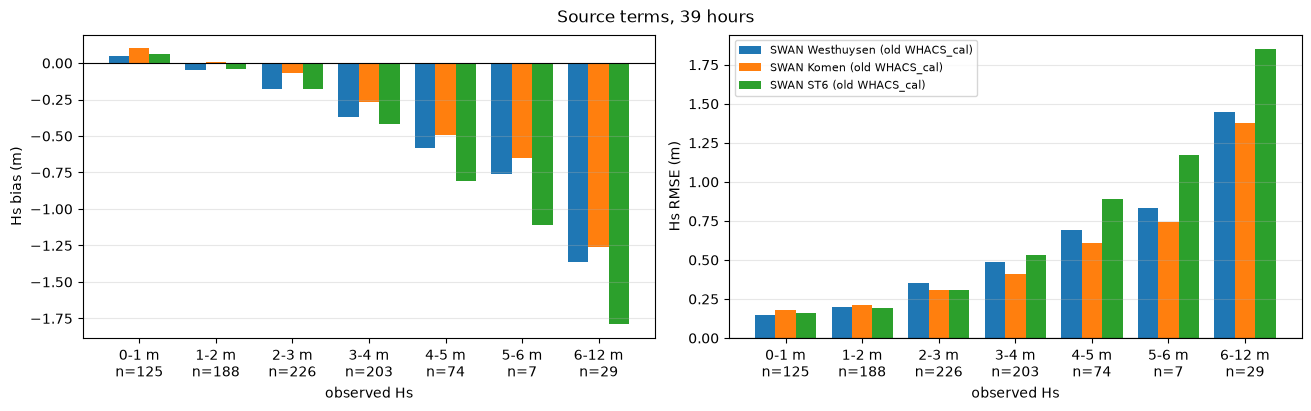

In [3]:
d.plot_by_class(
    "swan_source_terms",
    ["SWAN Westhuysen (old WHACS_cal)", "SWAN Komen (old WHACS_cal)", "SWAN ST6 (old WHACS_cal)"],
    "Source terms, 39 hours",
);

**Decision: `GEN3 KOMEN`.** Best from 2 m up (storm RMSE 0.35 vs 0.41 Westhuysen and
ST6). ST6 is worse everywhere above 3 m, needs 16 GB per task and runs twice as long
(median 37 vs 20 min). Komen hits the 50-iteration limit in 6 of 39 hours (accuracy
≥ 83 %).

## 2. Whitecapping in the no-wind goal cases

The goal cases have no wind. SWAN still applies whitecapping, which removes the energy
of steep seas. Hs ratio SWAN / SnapWave (energy weighted, sites with ≥ 25 % of the
offshore Hs), by case steepness and depth.

In [4]:
d.ratio_table("swan_whitecapping")

variant          SWAN default  SWAN OFF WCAP
steepness where                             
0.00-0.01 <18m          0.770          0.771
          deep          0.884          0.884
0.01-0.02 <18m          0.879          0.887
          deep          0.914          0.923
0.02-0.03 <18m          0.977          0.998
          deep          0.969          1.015
0.03-0.04 <18m          0.882          0.947
          deep          0.923          1.000
0.04-0.07 <18m          0.773          0.940
          deep          0.753          0.953

**Decision: `OFF WCAP` in the goal cases** (no wind, so no whitecapping either).
Steep cases go from 0.75 to 0.95 of SnapWave; gentle
ones do not change. With wind, Komen switches whitecapping back on.

## 3. Offshore forcing

Same physics (Komen), three forcings: the old WHACS_cal (directional energy fit
only), the new WHACS_cal (the same fit plus a satellite-only quantile mapping of the
storm tail, notebook 07b) and ERA5_cal.

In [5]:
d.buoy_table("swan_forcing_numerics", ["SWAN Komen (old WHACS_cal)", "SWAN Komen (WHACS_cal)", "SWAN Komen (ERA5_cal)"])

label,SWAN Komen (old WHACS_cal),SWAN Komen (WHACS_cal),SWAN Komen (ERA5_cal)
group,,,
calm,+0.05 / 0.17 (198),+0.03 / 0.17 (198),+0.02 / 0.17 (198)
storm,-0.13 / 0.35 (479),-0.14 / 0.35 (479),-0.07 / 0.35 (479)
xaver,-0.46 / 0.72 (175),-0.40 / 0.62 (175),-0.24 / 0.47 (175)
obs 0-1 m,+0.10 / 0.18 (125),+0.09 / 0.18 (125),+0.07 / 0.17 (125)
obs 1-2 m,+0.01 / 0.21 (188),+0.00 / 0.21 (188),+0.02 / 0.23 (188)
obs 2-3 m,-0.07 / 0.31 (226),-0.09 / 0.32 (226),-0.02 / 0.33 (226)
obs 3-4 m,-0.27 / 0.41 (203),-0.27 / 0.41 (203),-0.20 / 0.41 (203)
obs 4-5 m,-0.49 / 0.61 (74),-0.44 / 0.59 (74),-0.25 / 0.49 (74)
obs 5-6 m,-0.65 / 0.74 (7),-0.58 / 0.68 (7),-0.31 / 0.45 (7)


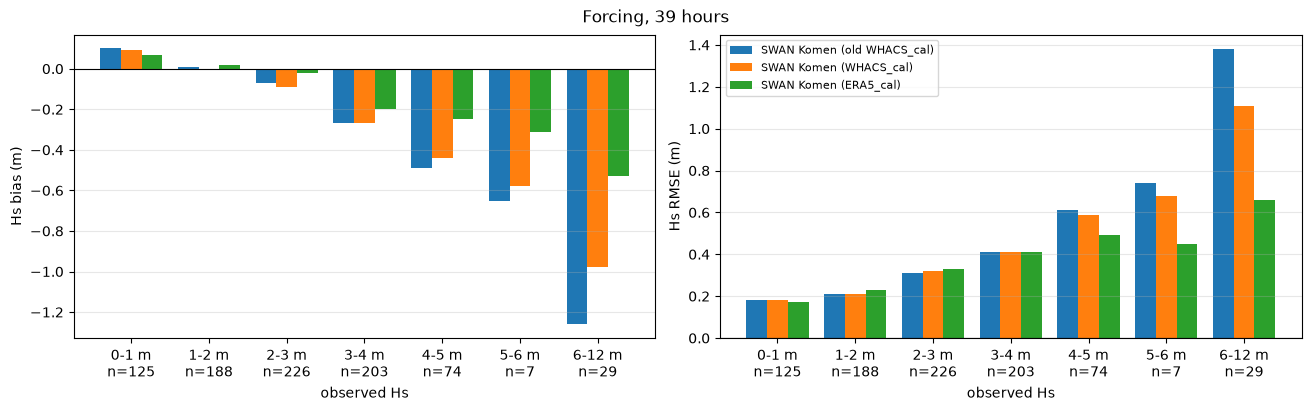

In [6]:
d.plot_by_class(
    "swan_forcing_numerics",
    ["SWAN Komen (old WHACS_cal)", "SWAN Komen (WHACS_cal)", "SWAN Komen (ERA5_cal)"],
    "Forcing, 39 hours",
);

**Decision: the quantile mapping stays in 07b** (Xaver RMSE 0.72 → 0.62; against 9
deep buoys 1979–2023: RMSE 0.27 → 0.25, p99.99 −1.06 → −0.14 m). ERA5_cal is better
still in Xaver (0.47). The forcing for the dynamic runs is **open**: below 3 m the
two tie, and the storm advantage of ERA5_cal rests mostly on Xaver (section 5).

## 4. Numerics with no effect

A water-level field instead of one level per case, `BREAKING BKD`, 100 instead of 50
iterations, no triads, and 5° instead of 10° directions.

In [7]:
d.buoy_table("swan_forcing_numerics", ["SWAN Komen (old WHACS_cal)", "SWAN Komen (old WHACS_cal), water-level field", "SWAN Komen (old WHACS_cal), BREAKING BKD"])

label,SWAN Komen (old WHACS_cal),"SWAN Komen (old WHACS_cal), water-level field","SWAN Komen (old WHACS_cal), BREAKING BKD"
group,,,
calm,+0.05 / 0.17 (198),+0.05 / 0.17 (198),+0.05 / 0.17 (198)
storm,-0.13 / 0.35 (479),-0.13 / 0.35 (479),-0.12 / 0.35 (479)
xaver,-0.46 / 0.72 (175),-0.47 / 0.71 (175),-0.46 / 0.73 (175)
obs 0-1 m,+0.10 / 0.18 (125),+0.10 / 0.18 (125),+0.10 / 0.19 (125)
obs 1-2 m,+0.01 / 0.21 (188),-0.00 / 0.19 (188),+0.04 / 0.21 (188)
obs 2-3 m,-0.07 / 0.31 (226),-0.07 / 0.31 (226),-0.06 / 0.31 (226)
obs 3-4 m,-0.27 / 0.41 (203),-0.27 / 0.41 (203),-0.26 / 0.41 (203)
obs 4-5 m,-0.49 / 0.61 (74),-0.48 / 0.60 (74),-0.51 / 0.65 (74)
obs 5-6 m,-0.65 / 0.74 (7),-0.62 / 0.72 (7),-0.87 / 0.96 (7)


In [8]:
d.ratio_table("swan_friction_triads")[["SWAN OFF WCAP", "SWAN OFF WCAP, no triads"]]

variant          SWAN OFF WCAP  SWAN OFF WCAP, no triads
steepness where                                         
0.00-0.01 <18m           0.771                     0.766
          deep           0.884                     0.884
0.01-0.02 <18m           0.887                     0.885
          deep           0.923                     0.923
0.02-0.03 <18m           0.998                     0.999
          deep           1.015                     1.014
0.03-0.04 <18m           0.947                     0.947
          deep           1.000                     1.000
0.04-0.07 <18m           0.940                     0.940
          deep           0.953                     0.953

In [9]:
d.load("swan_directions").describe().round(3)

,case,ratio
count,40.000,40.000
mean,2759.825,0.991
std,1239.149,0.062
min,821.000,0.630
25%,1765.250,0.998
50%,2792.000,0.999
75%,3656.500,1.002
max,4977.000,1.090


**Decision: keep the simple settings.** The water-level field changes the scores by
≤ 0.02 m; `BKD` changes nothing below 5 m and is worse at 5–6 m (RMSE 0.74 → 0.96,
7 pairs); triads do not change Hs; 100 iterations
change Hs by +0.003 m on average (p99 0.056 m) at up to twice the cost; 5° directions
leave 37 of 40 cases within 1 % (two narrow-swell cases move, and only 0.6–1.6 % of
the partition energy has a spreading under 10°) at twice the cost. `NUMERIC STOPC`
stays at the manual defaults.

## 5. Bottom friction

JONSWAP 0.038 (the manual's value for sandy bottoms) against 0.019 (its value for
smoother seafloors). First the 39 hours, then 120 other hours of 2013 that the
choice was not tuned on.

In [10]:
d.buoy_table("swan_friction", ["SWAN Komen (WHACS_cal)", "SWAN Komen (WHACS_cal), friction 0.019", "SWAN Komen (ERA5_cal)", "SWAN Komen (ERA5_cal), friction 0.019"])

label,SWAN Komen (WHACS_cal),"SWAN Komen (WHACS_cal), friction 0.019",SWAN Komen (ERA5_cal),"SWAN Komen (ERA5_cal), friction 0.019"
group,,,,
calm,+0.03 / 0.17 (198),+0.06 / 0.17 (198),+0.02 / 0.17 (198),+0.04 / 0.17 (198)
storm,-0.14 / 0.35 (479),-0.05 / 0.33 (479),-0.07 / 0.35 (479),+0.03 / 0.35 (479)
xaver,-0.40 / 0.62 (175),-0.31 / 0.56 (175),-0.24 / 0.47 (175),-0.14 / 0.43 (175)
obs 0-1 m,+0.09 / 0.18 (125),+0.11 / 0.19 (125),+0.07 / 0.17 (125),+0.09 / 0.18 (125)
obs 1-2 m,+0.00 / 0.21 (188),+0.05 / 0.23 (188),+0.02 / 0.23 (188),+0.07 / 0.26 (188)
obs 2-3 m,-0.09 / 0.32 (226),-0.00 / 0.31 (226),-0.02 / 0.33 (226),+0.07 / 0.35 (226)
obs 3-4 m,-0.27 / 0.41 (203),-0.18 / 0.36 (203),-0.20 / 0.41 (203),-0.11 / 0.37 (203)
obs 4-5 m,-0.44 / 0.59 (74),-0.34 / 0.52 (74),-0.25 / 0.49 (74),-0.12 / 0.44 (74)
obs 5-6 m,-0.58 / 0.68 (7),-0.49 / 0.61 (7),-0.31 / 0.45 (7),-0.20 / 0.38 (7)


In [11]:
d.buoy_table("swan_120h")

label,"SWAN Komen (WHACS_cal), friction 0.038","SWAN Komen (WHACS_cal), friction 0.019","SWAN Komen (ERA5_cal), friction 0.019"
group,,,
all,-0.04 / 0.31 (2565),+0.01 / 0.30 (2565),+0.01 / 0.28 (2565)
obs 0-1 m,+0.06 / 0.19 (985),+0.09 / 0.21 (985),+0.06 / 0.19 (985)
obs 1-2 m,-0.03 / 0.27 (893),+0.02 / 0.28 (893),+0.01 / 0.28 (893)
obs 2-3 m,-0.13 / 0.35 (482),-0.07 / 0.34 (482),-0.06 / 0.34 (482)
obs 3-4 m,-0.19 / 0.39 (145),-0.11 / 0.36 (145),-0.02 / 0.35 (145)
obs 4-5 m,-0.30 / 0.52 (27),-0.19 / 0.47 (27),+0.09 / 0.40 (27)
obs 5-6 m,-0.79 / 0.96 (13),-0.66 / 0.86 (13),-0.19 / 0.50 (13)
obs 6-12 m,-1.31 / 1.39 (20),-1.17 / 1.27 (20),-0.50 / 0.62 (20)


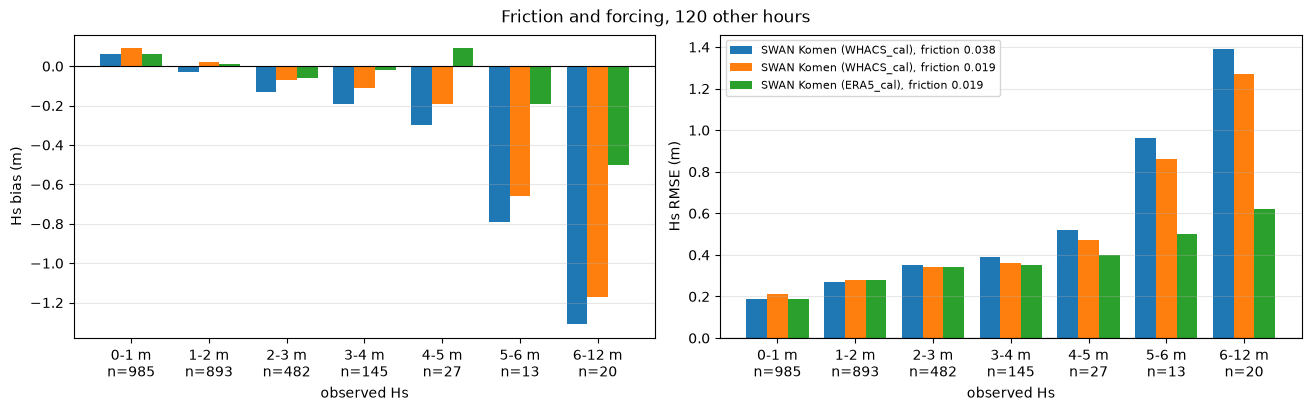

In [12]:
d.plot_by_class(
    "swan_120h",
    ["SWAN Komen (WHACS_cal), friction 0.038", "SWAN Komen (WHACS_cal), friction 0.019", "SWAN Komen (ERA5_cal), friction 0.019"],
    "Friction and forcing, 120 other hours",
);

**Decision: friction 0.019** in both templates. On the 120 hours RMSE 0.31 → 0.30,
better above 3 m (3–4 m 0.39 → 0.36, 6–12 m 1.39 → 1.27), slightly worse below 1 m
(bias +0.06 → +0.09). On these hours ERA5_cal again wins above 4 m, but 8 of them
fall on the Xaver days and 3 on St Jude.

## 6. Why the dynamic runs have wind

Same hours with and without wind (goal physics), then 500 hours of 2013 without wind.

In [13]:
d.buoy_table("swan_wind")

label,SWAN no wind (WHACS_cal),SWAN Komen (WHACS_cal),"SWAN Komen (WHACS_cal), friction 0.019"
group,,,
calm,-0.20 / 0.35 (198),+0.03 / 0.17 (198),+0.06 / 0.17 (198)
storm,-0.26 / 0.41 (479),-0.14 / 0.35 (479),-0.05 / 0.33 (479)
xaver,-0.69 / 0.86 (175),-0.40 / 0.62 (175),-0.31 / 0.56 (175)
obs 0-1 m,-0.09 / 0.23 (125),+0.09 / 0.18 (125),+0.11 / 0.19 (125)
obs 1-2 m,-0.24 / 0.38 (188),+0.00 / 0.21 (188),+0.05 / 0.23 (188)
obs 2-3 m,-0.25 / 0.38 (226),-0.09 / 0.32 (226),-0.00 / 0.31 (226)
obs 3-4 m,-0.40 / 0.56 (203),-0.27 / 0.41 (203),-0.18 / 0.36 (203)
obs 4-5 m,-0.72 / 0.87 (74),-0.44 / 0.59 (74),-0.34 / 0.52 (74)
obs 5-6 m,-0.97 / 1.10 (7),-0.58 / 0.68 (7),-0.49 / 0.61 (7)


In [14]:
d.buoy_table("swan_no_wind_500h")

label,SWAN no wind (WHACS_cal),SnapWave production (old WHACS_cal)
group,,
all,-0.30 / 0.50 (10686),+0.21 / 0.49 (10686)
obs 0-1 m,-0.12 / 0.23 (4066),+0.27 / 0.54 (4066)
obs 1-2 m,-0.30 / 0.45 (3478),+0.27 / 0.39 (3478)
obs 2-3 m,-0.44 / 0.62 (1845),+0.24 / 0.41 (1845)
obs 3-4 m,-0.56 / 0.73 (838),+0.05 / 0.38 (838)
obs 4-5 m,-0.85 / 1.03 (288),-0.36 / 0.58 (288)
obs 5-6 m,-1.13 / 1.26 (74),-0.96 / 1.05 (74)
obs 6-12 m,-1.12 / 1.24 (97),-1.42 / 1.49 (97)
d 0-15 m,-0.23 / 0.39 (4485),+0.24 / 0.46 (4485)


**Decision: dynamic runs keep wind; the linear sum has none yet** (`hywaves/WIND.md`).
Without wind Hs is low everywhere (500 hours: bias −0.30, RMSE 0.50 m); wind adds 22 %
in calm hours and 4–6 % in storms (median Hs ratio). Stationary runs stay: a
non-stationary Xaver run gained no Hs, and the lag study found none.

## 7. Wind input

`AGROW` (linear growth, off unless requested) and ERA5 wind × 1.1 (ERA5 storm winds
are often low).

In [15]:
d.buoy_table("swan_wind_input")

label,SnapWave production (old WHACS_cal),"SWAN Komen (WHACS_cal), friction 0.019","SWAN Komen AGROW (WHACS_cal), friction 0.019","SWAN Komen (WHACS_cal), friction 0.019, wind x 1.1","SWAN Komen (ERA5_cal), friction 0.019","SWAN Komen (ERA5_cal), friction 0.019, wind x 1.1"
group,,,,,,
calm,+0.29 / 0.36 (198),+0.06 / 0.17 (198),+0.06 / 0.17 (198),+0.16 / 0.25 (198),+0.04 / 0.17 (198),+0.14 / 0.24 (198)
storm,+0.23 / 0.43 (479),-0.05 / 0.33 (479),-0.05 / 0.33 (479),+0.16 / 0.39 (479),+0.03 / 0.35 (479),+0.24 / 0.45 (479)
xaver,-0.36 / 0.76 (175),-0.31 / 0.56 (175),-0.30 / 0.56 (175),-0.09 / 0.50 (175),-0.14 / 0.43 (175),+0.07 / 0.46 (175)
obs 0-1 m,+0.31 / 0.38 (125),+0.11 / 0.19 (125),+0.12 / 0.19 (125),+0.19 / 0.26 (125),+0.09 / 0.18 (125),+0.16 / 0.25 (125)
obs 1-2 m,+0.32 / 0.40 (188),+0.05 / 0.23 (188),+0.05 / 0.23 (188),+0.18 / 0.32 (188),+0.07 / 0.26 (188),+0.20 / 0.35 (188)
obs 2-3 m,+0.31 / 0.44 (226),-0.00 / 0.31 (226),-0.00 / 0.31 (226),+0.22 / 0.42 (226),+0.07 / 0.35 (226),+0.30 / 0.48 (226)
obs 3-4 m,+0.05 / 0.38 (203),-0.18 / 0.36 (203),-0.18 / 0.36 (203),+0.05 / 0.36 (203),-0.11 / 0.37 (203),+0.13 / 0.43 (203)
obs 4-5 m,-0.34 / 0.59 (74),-0.34 / 0.52 (74),-0.34 / 0.51 (74),-0.07 / 0.45 (74),-0.12 / 0.44 (74),+0.14 / 0.51 (74)
obs 5-6 m,-0.94 / 0.99 (7),-0.49 / 0.61 (7),-0.49 / 0.61 (7),-0.27 / 0.48 (7),-0.20 / 0.38 (7),+0.01 / 0.43 (7)


**Decision: neither.** `AGROW` changes nothing. Wind × 1.1 helps Xaver (RMSE 0.56 →
0.50) but spoils everything else (calm 0.17 → 0.25, storm 0.33 → 0.39): ERA5 wind is
right on average.

## Template physics (result)

Goal cases (`templates-swan-metamodel/INPUT`):

```
OFF QUAD
OFF WCAP
BREAKING CONSTANT 1.0 0.73
FRICTION JONSWAP CONSTANT 0.019
TRIAD
NUMERIC STOPC 0.005 0.01 0.005 99.5 STATIONARY 50
```

Dynamic runs (`templates-swan-dynamic/INPUT`): `GEN3 KOMEN` with wind, else
`OFF QUAD` + `OFF WCAP`; the rest as above; `TABLE` with `HSIGN TPS TMM10 DIR DSPR` and
2D spectra at the buoys (`SPECOUT`). Grid: `CIRCLE 36 0.03 1.0 36`.